# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Himawan Wisnu Pramuditya
- **Email:** wphimawan9b@gmail.com
- **ID Dicoding:** himawan_wisnu_bwOr

## Menentukan Pertanyaan Bisnis

- **Pertanyaan 1:** Kategori produk apa saja yang menjadi 10 besar penyumbang total pendapatan (revenue) pada periode Januari sampai Agustus 2018, dan bagaimana perubahan persentase pendapatannya dibandingkan periode Januari sampai Agustus 2017?
- **Pertanyaan 2:** Seberapa besar selisih rata-rata skor review antara pesanan yang terlambat dan yang tepat waktu, dan di negara bagian (state) mana persentase keterlambatan pengiriman paling tinggi selama Januari 2017 sampai Agustus 2018?

## Import Semua Packages/Library yang Digunakan

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium.plugins import HeatMap
from matplotlib.ticker import FuncFormatter

%matplotlib inline
sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data

#### Load df customers

In [2]:
path = "E-Commerce Public Dataset/"

customers_df = pd.read_csv(path + "customers_dataset.csv")
customers_df.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


#### Load df orders

In [3]:
orders_df = pd.read_csv(path + "orders_dataset.csv")
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


#### Load df order items

In [4]:
order_items_df = pd.read_csv(path + "order_items_dataset.csv")
order_items_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


#### Load df products

In [5]:
products_df = pd.read_csv(path + "products_dataset.csv")
products_df.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


#### Load df product category translation

In [6]:
category_df = pd.read_csv(path + "product_category_name_translation.csv")
category_df.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


#### Load df order reviews

In [7]:
reviews_df = pd.read_csv(path + "order_reviews_dataset.csv")
reviews_df.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


#### Load df order payments

In [8]:
payments_df = pd.read_csv(path + "order_payments_dataset.csv")
payments_df.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [9]:
print(orders_df.shape)

(99441, 8)


**Insight:**
- Data terdiri dari 7 tabel yang saling berelasi, yaitu customers, orders, order items, products, product category translation, order reviews, dan order payments.
- Tabel orders dan customers masing-masing berisi 99.441 baris, sedangkan order items berisi 112.650 baris karena satu pesanan bisa memuat lebih dari satu produk.
- Nama kategori produk pada tabel products masih berbahasa Portugis, sehingga perlu digabung dengan tabel category translation agar mudah dibaca.
- Kolom tanggal pada tabel orders masih terbaca sebagai teks (object), jadi perlu diubah ke tipe datetime pada tahap cleaning.

### Assessing Data

#### Identifying missing value problem

In [10]:
print("Missing value pada orders_df:")
print(orders_df.isna().sum())
print()
print("Missing value pada products_df:")
print(products_df.isna().sum())
print()
print("Missing value pada reviews_df:")
print(reviews_df.isna().sum())

Missing value pada orders_df:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Missing value pada products_df:
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Missing value pada reviews_df:
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64


**Steps to Take:**
- Pada orders_df, kolom order_approved_at, order_delivered_carrier_date, dan order_delivered_customer_date memiliki nilai kosong. Sebagian besar terjadi pada pesanan yang belum berstatus delivered (dibatalkan atau masih diproses), sehingga wajar. Baris tidak dihapus dari tabel utama, tetapi analisis pengiriman akan difokuskan pada pesanan berstatus delivered.
- Pada products_df, kolom product_category_name kosong pada 610 produk. Nilai kosong ini diisi dengan label "unknown" agar pendapatan produk tersebut tetap terhitung.
- Pada reviews_df, kolom review_comment_title dan review_comment_message banyak kosong karena pelanggan tidak wajib menulis komentar. Kolom ini tidak dipakai dalam analisis sehingga dibiarkan.

#### Identifying invalid data type problem

In [11]:
orders_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


**Steps to Take:**
- Kolom tanggal pada orders_df (order_purchase_timestamp, order_approved_at, order_delivered_carrier_date, order_delivered_customer_date, order_estimated_delivery_date) masih bertipe object (teks). Kolom-kolom ini diubah ke tipe datetime agar bisa dipakai untuk filter periode dan menghitung selisih hari.

#### Identifying duplicate data problem

In [12]:
tabel = {
    "customers_df": customers_df,
    "orders_df": orders_df,
    "order_items_df": order_items_df,
    "products_df": products_df,
    "category_df": category_df,
    "reviews_df": reviews_df,
    "payments_df": payments_df
}

for nama, df in tabel.items():
    print(f"{nama}: {df.duplicated().sum()} baris duplikat penuh")

print()
print("order_id ganda pada reviews_df:", reviews_df["order_id"].duplicated().sum())
print("review_id ganda pada reviews_df:", reviews_df["review_id"].duplicated().sum())

customers_df: 0 baris duplikat penuh
orders_df: 0 baris duplikat penuh
order_items_df: 0 baris duplikat penuh
products_df: 0 baris duplikat penuh
category_df: 0 baris duplikat penuh
reviews_df: 0 baris duplikat penuh
payments_df: 0 baris duplikat penuh

order_id ganda pada reviews_df: 551
review_id ganda pada reviews_df: 814


**Steps to Take:**
- Tidak ada baris duplikat penuh pada semua tabel.
- Namun pada reviews_df terdapat order_id yang muncul lebih dari sekali (satu pesanan memiliki lebih dari satu review). Jika langsung digabung dengan orders_df, baris pesanan akan berlipat ganda dan menggembungkan hasil perhitungan. Solusinya, review diambil satu per pesanan (review terbaru berdasarkan review_answer_timestamp) sebelum proses merge.

#### Identifying inconsistent value problem

In [13]:
# Pesanan berstatus delivered tetapi tanggal diterima pelanggan kosong
delivered_tanpa_tanggal = orders_df[
    (orders_df["order_status"] == "delivered") &
    (orders_df["order_delivered_customer_date"].isna())
]
print("Delivered tanpa tanggal diterima:", len(delivered_tanpa_tanggal))

# Pesanan tidak berstatus delivered tetapi memiliki tanggal diterima
bukan_delivered_ada_tanggal = orders_df[
    (orders_df["order_status"] != "delivered") &
    (orders_df["order_delivered_customer_date"].notna())
]
print("Bukan delivered tetapi ada tanggal diterima:", len(bukan_delivered_ada_tanggal))

# Kategori produk yang tidak ada di tabel terjemahan
kategori_tanpa_terjemahan = set(products_df["product_category_name"].dropna()) - set(category_df["product_category_name"])
print("Kategori tanpa terjemahan:", kategori_tanpa_terjemahan)

Delivered tanpa tanggal diterima: 8
Bukan delivered tetapi ada tanggal diterima: 6
Kategori tanpa terjemahan: {'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}


**Steps to Take:**
- 8 pesanan berstatus delivered tidak memiliki tanggal diterima pelanggan, dan 6 pesanan non-delivered justru memiliki tanggal tersebut. Karena jumlahnya sangat kecil dan tidak bisa diverifikasi, baris-baris ini dikeluarkan dari analisis ketepatan pengiriman.
- Dua kategori (portateis_cozinha_e_preparadores_de_alimentos dan pc_gamer) tidak memiliki terjemahan Inggris. Terjemahannya ditambahkan secara manual agar tidak muncul sebagai nilai kosong setelah merge.

#### Identifying outlier problem

count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64

Batas atas outlier harga: 277.4
Jumlah outlier harga: 8427


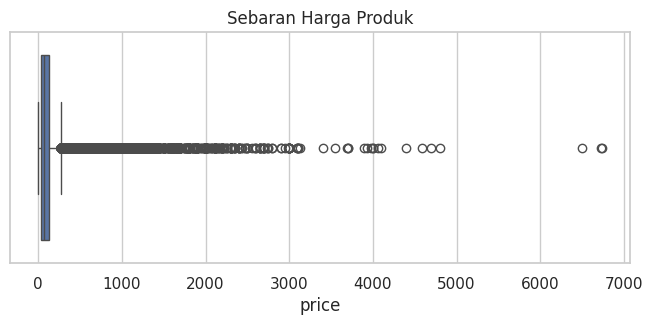

In [14]:
print(order_items_df["price"].describe())

Q1 = order_items_df["price"].quantile(0.25)
Q3 = order_items_df["price"].quantile(0.75)
IQR = Q3 - Q1
batas_atas = Q3 + 1.5 * IQR

outlier_price = order_items_df[order_items_df["price"] > batas_atas]
print()
print("Batas atas outlier harga:", batas_atas)
print("Jumlah outlier harga:", len(outlier_price))

plt.figure(figsize=(8, 3))
sns.boxplot(x=order_items_df["price"])
plt.title("Sebaran Harga Produk")
plt.show()

**Steps to Take:**
- Harga produk sangat condong ke kanan, dengan harga maksimum 6.735 sedangkan median hanya sekitar 75. Terdapat 8.427 baris di atas batas IQR. Nilai ini adalah harga produk mahal yang sah (misalnya elektronik atau furnitur), bukan kesalahan input, sehingga outlier dipertahankan agar total pendapatan tidak berkurang.

In [15]:
orders_df.isna().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


**Insight:**
- Kualitas data secara umum baik karena tidak ada baris duplikat penuh pada semua tabel.
- Masalah utama ada pada tipe data tanggal, nilai kosong pada kolom pengiriman, dan satu pesanan yang bisa memiliki lebih dari satu review.
- Terdapat 610 produk tanpa kategori dan 2 kategori tanpa terjemahan Inggris yang perlu ditangani sebelum menjawab pertanyaan 1.
- Outlier harga bukan kesalahan data sehingga tidak dibuang.

### Cleaning Data

#### Fixing missing value problem

In [16]:
# Mengisi kategori produk yang kosong dengan label "unknown"
products_df["product_category_name"] = products_df["product_category_name"].fillna("unknown")

print("Jumlah kategori kosong:", products_df["product_category_name"].isna().sum())
print("Jumlah produk berkategori unknown:", (products_df["product_category_name"] == "unknown").sum())

Jumlah kategori kosong: 0
Jumlah produk berkategori unknown: 610


#### Fixing invalid data type problem

In [17]:
kolom_tanggal_orders = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for kolom in kolom_tanggal_orders:
    orders_df[kolom] = pd.to_datetime(orders_df[kolom])

reviews_df["review_creation_date"] = pd.to_datetime(reviews_df["review_creation_date"])
reviews_df["review_answer_timestamp"] = pd.to_datetime(reviews_df["review_answer_timestamp"])

orders_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 6.1+ MB


#### Fixing duplicate data problem

In [18]:
print("Jumlah baris reviews sebelum:", len(reviews_df))

# Ambil review terbaru untuk setiap pesanan
reviews_df = (
    reviews_df
    .sort_values("review_answer_timestamp")
    .drop_duplicates(subset="order_id", keep="last")
    .reset_index(drop=True)
)

print("Jumlah baris reviews sesudah:", len(reviews_df))
print("order_id ganda tersisa:", reviews_df["order_id"].duplicated().sum())

Jumlah baris reviews sebelum: 99224
Jumlah baris reviews sesudah: 98673
order_id ganda tersisa: 0


#### Fixing inconsistent value problem

In [19]:
# 1. Hapus pesanan yang status dan tanggal pengirimannya tidak konsisten
delivered_tanpa_tanggal = (
    (orders_df["order_status"] == "delivered") &
    (orders_df["order_delivered_customer_date"].isna())
)
bukan_delivered_ada_tanggal = (
    (orders_df["order_status"] != "delivered") &
    (orders_df["order_delivered_customer_date"].notna())
)

print("Jumlah baris orders sebelum:", len(orders_df))
orders_df = orders_df[~(delivered_tanpa_tanggal | bukan_delivered_ada_tanggal)].reset_index(drop=True)
print("Jumlah baris orders sesudah:", len(orders_df))

# 2. Tambahkan terjemahan untuk kategori yang belum ada
terjemahan_tambahan = pd.DataFrame({
    "product_category_name": [
        "portateis_cozinha_e_preparadores_de_alimentos",
        "pc_gamer",
        "unknown"
    ],
    "product_category_name_english": [
        "portable_kitchen_and_food_preparers",
        "pc_gamer",
        "unknown"
    ]
})

category_df = pd.concat([category_df, terjemahan_tambahan], ignore_index=True)

# Pastikan semua kategori produk sudah punya terjemahan
kategori_tersisa = set(products_df["product_category_name"]) - set(category_df["product_category_name"])
print("Kategori tanpa terjemahan:", kategori_tersisa)

Jumlah baris orders sebelum: 99441
Jumlah baris orders sesudah: 99427
Kategori tanpa terjemahan: set()


**Insight:**
- Sebanyak 610 produk tanpa kategori diberi label "unknown" sehingga pendapatannya tetap terhitung dalam analisis.
- Seluruh kolom tanggal pada orders_df dan reviews_df sudah bertipe datetime sehingga bisa dipakai untuk filter periode dan menghitung selisih hari pengiriman.
- Tabel reviews_df berkurang dari 99.224 menjadi 98.673 baris karena hanya review terbaru per pesanan yang disimpan, sehingga merge dengan orders_df tidak menggandakan baris.
- Sebanyak 14 pesanan yang statusnya tidak konsisten dihapus (8 delivered tanpa tanggal terima dan 6 non-delivered dengan tanggal terima), sehingga orders_df tersisa 99.427 baris.
- Dua kategori tanpa terjemahan sudah dilengkapi, dan outlier harga sengaja dipertahankan karena bukan kesalahan data.

## Exploratory Data Analysis (EDA)

### Explore data orders

In [20]:
orders_df.describe(include="all")

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99427,99427,99427,99427,99267,97645,96470,99427
unique,99427,99427,8,NaN,NaN,NaN,NaN,NaN
top,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,NaN,NaN,NaN,NaN,NaN
freq,1,1,96470,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,2017-12-31 09:03:23.721957120,2017-12-31 18:55:39.589531648,2018-01-04 22:07:02.372451072,2018-01-14 12:41:33.581683456,2018-01-24 03:26:44.678809600
min,NaN,NaN,NaN,2016-09-04 21:15:19,2016-09-15 12:16:38,2016-10-08 10:34:01,2016-10-11 13:46:32,2016-09-30 00:00:00
25%,NaN,NaN,NaN,2017-09-12 15:11:19.500000,2017-09-12 23:52:50.500000,2017-09-15 22:31:52,2017-09-25 22:15:09.500000,2017-10-03 00:00:00
50%,NaN,NaN,NaN,2018-01-18 23:04:36,2018-01-19 11:36:13,2018-01-24 16:09:18,2018-02-02 19:32:21,2018-02-15 00:00:00
75%,NaN,NaN,NaN,2018-05-04 15:29:15.500000,2018-05-04 20:15:20.500000,2018-05-08 13:36:00,2018-05-15 22:54:48.500000,2018-05-25 00:00:00
max,NaN,NaN,NaN,2018-10-17 17:30:18,2018-09-03 17:40:06,2018-09-11 19:48:28,2018-10-17 13:22:46,2018-11-12 00:00:00


In [21]:
orders_df["order_status"].value_counts()

,count
order_status,
delivered,96470
shipped,1107
canceled,619
unavailable,609
invoiced,314
processing,301
created,5
approved,2


### Explore revenue per kategori produk

In [22]:
# Gabungkan order items dengan orders, products, dan terjemahan kategori
items_df = order_items_df.merge(
    orders_df[["order_id", "order_status", "order_purchase_timestamp"]],
    on="order_id", how="inner"
)
items_df = items_df.merge(
    products_df[["product_id", "product_category_name"]],
    on="product_id", how="left"
)
items_df = items_df.merge(category_df, on="product_category_name", how="left")

# Hanya pesanan delivered
items_df = items_df[items_df["order_status"] == "delivered"].copy()
items_df["tahun"] = items_df["order_purchase_timestamp"].dt.year
items_df["bulan"] = items_df["order_purchase_timestamp"].dt.month

print("Jumlah kategori tanpa terjemahan:", items_df["product_category_name_english"].isna().sum())
items_df.head()

Jumlah kategori tanpa terjemahan: 0


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,order_status,order_purchase_timestamp,product_category_name,product_category_name_english,tahun,bulan
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,delivered,2017-09-13 08:59:02,cool_stuff,cool_stuff,2017,9
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,delivered,2017-04-26 10:53:06,pet_shop,pet_shop,2017,4
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,delivered,2018-01-14 14:33:31,moveis_decoracao,furniture_decor,2018,1
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,delivered,2018-08-08 10:00:35,perfumaria,perfumery,2018,8
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,delivered,2017-02-04 13:57:51,ferramentas_jardim,garden_tools,2017,2


In [23]:
# Periode yang dibandingkan: Januari sampai Agustus 2017 dan 2018
periode_df = items_df[(items_df["bulan"] <= 8) & (items_df["tahun"].isin([2017, 2018]))]

revenue_kategori = periode_df.pivot_table(
    index="product_category_name_english",
    columns="tahun",
    values="price",
    aggfunc="sum",
    fill_value=0
)

revenue_kategori["pertumbuhan_persen"] = (
    (revenue_kategori[2018] - revenue_kategori[2017]) / revenue_kategori[2017].replace(0, np.nan) * 100
)
revenue_kategori["kontribusi_2018_persen"] = revenue_kategori[2018] / revenue_kategori[2018].sum() * 100

top10_kategori = revenue_kategori.sort_values(2018, ascending=False).head(10)
top10_kategori.round(2)

tahun,2017,2018,pertumbuhan_persen,kontribusi_2018_persen
product_category_name_english,,,,
health_beauty,243521.70,755724.50,210.33,10.47
watches_gifts,201137.86,687577.20,241.84,9.53
bed_bath_table,254444.82,532358.85,109.22,7.38
sports_leisure,216545.33,517166.26,138.83,7.17
computers_accessories,214631.27,496158.31,131.17,6.87
housewares,127534.54,391823.46,207.23,5.43
furniture_decor,170858.58,381649.57,123.37,5.29
auto,125247.48,343288.30,174.09,4.76
baby,67998.26,250615.79,268.56,3.47


In [24]:
print("Total revenue Jan-Agu 2017:", round(revenue_kategori[2017].sum(), 2))
print("Total revenue Jan-Agu 2018:", round(revenue_kategori[2018].sum(), 2))

Total revenue Jan-Agu 2017: 2993277.13
Total revenue Jan-Agu 2018: 7217172.24


### Explore keterlambatan pengiriman dan skor review

In [25]:
# Gabungkan orders delivered dengan review dan data pelanggan
delivery_df = orders_df[orders_df["order_status"] == "delivered"].merge(
    reviews_df[["order_id", "review_score"]], on="order_id", how="left"
)
delivery_df = delivery_df.merge(
    customers_df[["customer_id", "customer_unique_id", "customer_state"]],
    on="customer_id", how="left"
)

# Pesanan terlambat jika diterima setelah tanggal estimasi
delivery_df["terlambat"] = (
    delivery_df["order_delivered_customer_date"] > delivery_df["order_estimated_delivery_date"]
)
delivery_df["lama_kirim_hari"] = (
    delivery_df["order_delivered_customer_date"] - delivery_df["order_purchase_timestamp"]
).dt.days

# Batasi periode Januari 2017 sampai Agustus 2018
delivery_df = delivery_df[
    (delivery_df["order_purchase_timestamp"] >= "2017-01-01") &
    (delivery_df["order_purchase_timestamp"] < "2018-09-01")
].copy()

print("Jumlah pesanan:", len(delivery_df))
print("Persentase pesanan terlambat:", round(delivery_df["terlambat"].mean() * 100, 2), "%")
delivery_df.head()

Jumlah pesanan: 96203
Persentase pesanan terlambat: 8.13 %


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,review_score,customer_unique_id,customer_state,terlambat,lama_kirim_hari
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,4.0,7c396fd4830fd04220f754e42b4e5bff,SP,False,8
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,4.0,af07308b275d755c9edb36a90c618231,BA,False,13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,5.0,3a653a41f6f9fc3d2a113cf8398680e8,GO,False,9
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,5.0,7c142cf63193a1473d2e66489a9ae977,RN,False,13
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,5.0,72632f0f9dd73dfee390c9b22eb56dd6,SP,False,2


In [26]:
# Rata-rata skor review: terlambat vs tepat waktu
delivery_df.groupby("terlambat")["review_score"].agg(["mean", "count"]).round(2)

,mean,count
terlambat,,
False,4.29,87902
True,2.57,7658


In [27]:
# Persentase keterlambatan dan rata-rata skor review per state
state_df = delivery_df.groupby("customer_state").agg(
    jumlah_pesanan=("order_id", "count"),
    persen_terlambat=("terlambat", lambda x: x.mean() * 100),
    rata_skor_review=("review_score", "mean")
).sort_values("persen_terlambat", ascending=False)

state_df.round(2)

,jumlah_pesanan,persen_terlambat,rata_skor_review
customer_state,,,
AL,396,23.99,3.85
MA,713,19.64,3.83
PI,475,16.00,3.99
CE,1273,15.40,3.94
SE,332,15.36,3.90
BA,3253,14.05,3.93
RJ,12310,13.52,3.97
TO,274,12.77,4.15
RR,40,12.50,3.90


In [28]:
delivery_df["lama_kirim_hari"].describe()

,lama_kirim_hari
count,96203.000000
mean,12.073854
std,9.535542
min,0.000000
25%,6.000000
50%,10.000000
75%,15.000000
max,209.000000


**Insight:**
- Total revenue periode Januari sampai Agustus naik dari sekitar 2,99 juta pada 2017 menjadi sekitar 7,22 juta pada 2018, atau tumbuh sekitar 141%.
- Kategori health_beauty menjadi penyumbang terbesar pada 2018 (sekitar 755 ribu, kontribusi 10,47%), diikuti watches_gifts (sekitar 687 ribu, 9,53%) dan bed_bath_table (sekitar 532 ribu, 7,38%).
- Kategori dengan pertumbuhan tinggi antara lain baby (sekitar 269%) dan watches_gifts (sekitar 242%), sedangkan cool_stuff hanya tumbuh sekitar 10% sehingga relatif stagnan.
- Sekitar 8,13% pesanan terlambat dari estimasi. Rata-rata skor review pesanan terlambat hanya sekitar 2,57, sedangkan pesanan tepat waktu sekitar 4,29, selisih sekitar 1,73 poin.
- State dengan persentase keterlambatan tertinggi adalah AL (sekitar 24%), MA (sekitar 19,6%), PI (16%), CE (15,4%), dan SE (15,4%). Sebaliknya, SP (5,9%), MG (5,6%), dan PR (5,0%) relatif rendah.
- Median lama pengiriman 10 hari, sedangkan rata-rata sekitar 12 hari karena ada pesanan yang sangat lama (maksimum 209 hari).

## Visualization & Explanatory Analysis

### Pertanyaan 1:

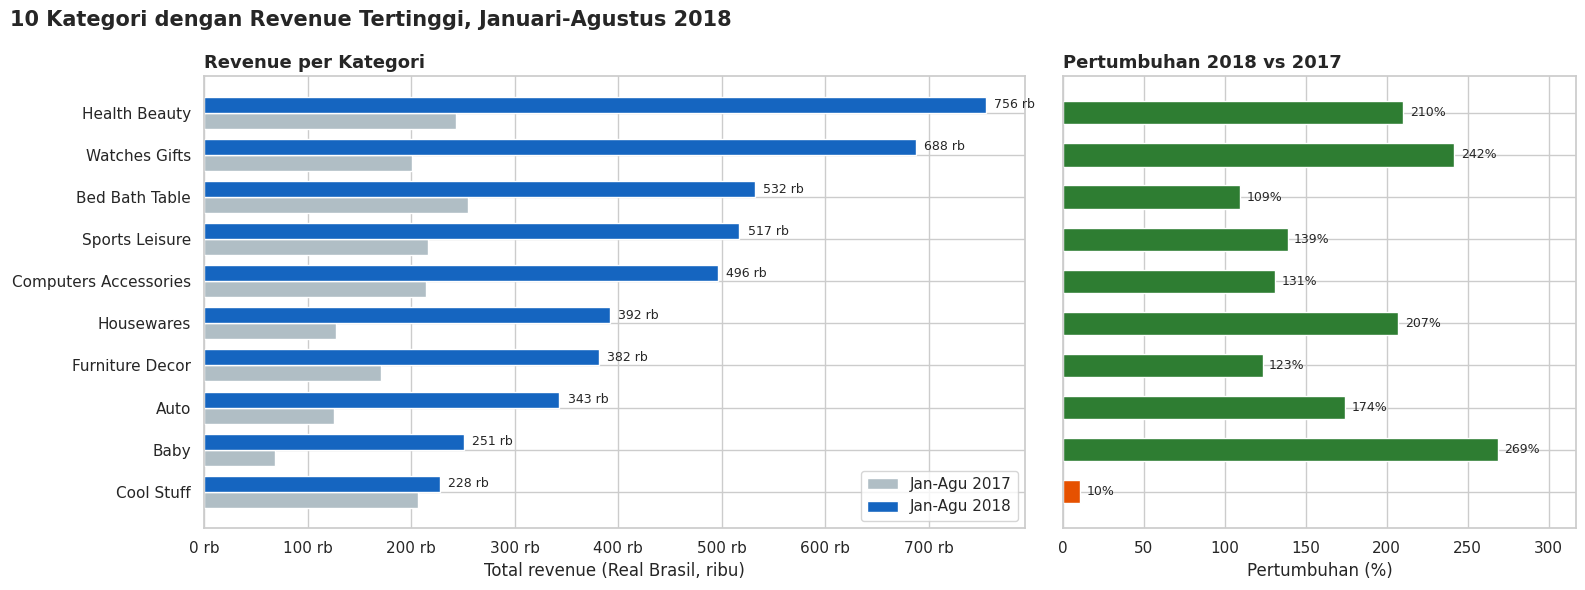

In [30]:
data_q1 = top10_kategori.reset_index().sort_values(2018, ascending=True)
data_q1["kategori"] = data_q1["product_category_name_english"].str.replace("_", " ").str.title()

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.6, 1]}, sharey=True)
y = np.arange(len(data_q1))
tinggi = 0.38

# Panel kiri: revenue 2017 vs 2018
axes[0].barh(y - tinggi/2, data_q1[2017], height=tinggi, color="#B0BEC5", label="Jan-Agu 2017")
axes[0].barh(y + tinggi/2, data_q1[2018], height=tinggi, color="#1565C0", label="Jan-Agu 2018")
axes[0].set_yticks(y)
axes[0].set_yticklabels(data_q1["kategori"])
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v/1000:,.0f} rb"))
axes[0].set_title("Revenue per Kategori", loc="left", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Total revenue (Real Brasil, ribu)")
axes[0].legend(loc="lower right")
for i, v in enumerate(data_q1[2018]):
    axes[0].text(v + 8000, i + tinggi/2, f"{v/1000:,.0f} rb", va="center", fontsize=9)

# Panel kanan: pertumbuhan, oranye jika di bawah 50%
warna = ["#E65100" if g < 50 else "#2E7D32" for g in data_q1["pertumbuhan_persen"]]
axes[1].barh(y, data_q1["pertumbuhan_persen"], color=warna, height=0.55)
axes[1].set_title("Pertumbuhan 2018 vs 2017", loc="left", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Pertumbuhan (%)")
axes[1].set_xlim(0, data_q1["pertumbuhan_persen"].max() * 1.18)
for i, g in enumerate(data_q1["pertumbuhan_persen"]):
    axes[1].text(g + 4, i, f"{g:,.0f}%", va="center", fontsize=9)

fig.suptitle("10 Kategori dengan Revenue Tertinggi, Januari-Agustus 2018",
             fontsize=15, fontweight="bold", x=0.01, ha="left")
plt.tight_layout()
plt.show()

### Pertanyaan 2:

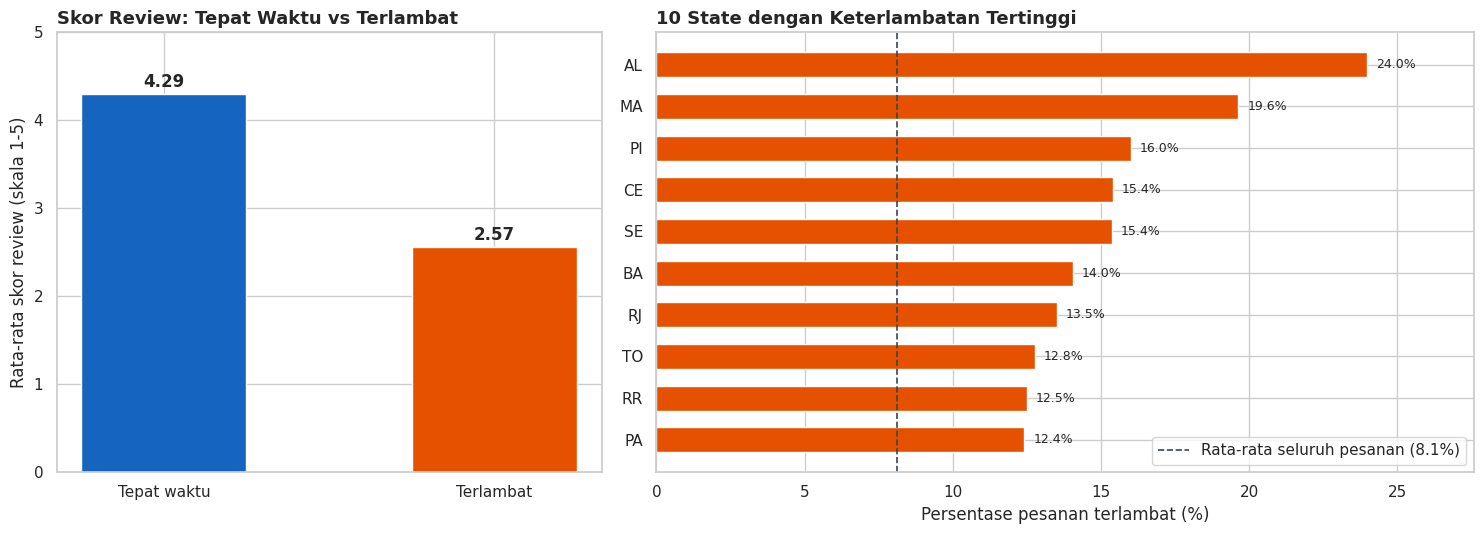

In [31]:
skor = delivery_df.groupby("terlambat")["review_score"].mean()
rata_terlambat = delivery_df["terlambat"].mean() * 100
top10_state = state_df.head(10).sort_values("persen_terlambat", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.5]})

# Panel kiri: skor review
label = ["Tepat waktu", "Terlambat"]
nilai = [skor[False], skor[True]]
axes[0].bar(label, nilai, color=["#1565C0", "#E65100"], width=0.5)
axes[0].set_ylim(0, 5)
axes[0].set_ylabel("Rata-rata skor review (skala 1-5)")
axes[0].set_title("Skor Review: Tepat Waktu vs Terlambat", loc="left", fontsize=13, fontweight="bold")
for i, v in enumerate(nilai):
    axes[0].text(i, v + 0.08, f"{v:.2f}", ha="center", fontweight="bold")

# Panel kanan: 10 state dengan keterlambatan tertinggi
axes[1].barh(top10_state.index, top10_state["persen_terlambat"], color="#E65100", height=0.6)
axes[1].axvline(rata_terlambat, color="#37474F", linestyle="--", linewidth=1.2,
                label=f"Rata-rata seluruh pesanan ({rata_terlambat:.1f}%)")
axes[1].legend(loc="lower right")
axes[1].set_xlabel("Persentase pesanan terlambat (%)")
axes[1].set_xlim(0, top10_state["persen_terlambat"].max() * 1.15)
axes[1].set_title("10 State dengan Keterlambatan Tertinggi", loc="left", fontsize=13, fontweight="bold")
for i, v in enumerate(top10_state["persen_terlambat"]):
    axes[1].text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)

plt.tight_layout()
plt.show()

**Insight:**
- Pada periode Januari sampai Agustus 2018, health_beauty menjadi kategori dengan revenue tertinggi (sekitar 756 ribu), diikuti watches_gifts (sekitar 688 ribu) dan bed_bath_table (sekitar 532 ribu).
- Hampir semua kategori 10 besar tumbuh di atas 100% dibanding periode yang sama pada 2017. Pertumbuhan tertinggi ada pada baby (sekitar 269%) dan watches_gifts (sekitar 242%).
- Cool_stuff adalah satu-satunya kategori 10 besar yang nyaris stagnan dengan pertumbuhan sekitar 10%.
- Pesanan terlambat mendapat skor review rata-rata 2,57, jauh di bawah pesanan tepat waktu yang mencapai 4,29.
- Kesepuluh state dengan keterlambatan tertinggi seluruhnya berada di atas rata-rata (8,1%). State AL menjadi yang terburuk dengan sekitar 24% pesanan terlambat, disusul MA (sekitar 19,6%) dan PI (16%).

## Analisis Lanjutan (Opsional)

**Insight:** (Opsional)
- xxx
- xxx

## Menyiapkan Data untuk Dashboard

In [37]:
import os

orders_delivered = orders_df[orders_df["order_status"] == "delivered"][[
    "order_id", "customer_id", "order_purchase_timestamp",
    "order_delivered_customer_date", "order_estimated_delivery_date"
]]

main_df = order_items_df[["order_id", "order_item_id", "product_id", "price"]].merge(
    orders_delivered, on="order_id", how="inner"
)
main_df = main_df.merge(products_df[["product_id", "product_category_name"]], on="product_id", how="left")
main_df = main_df.merge(category_df, on="product_category_name", how="left")
main_df = main_df.merge(reviews_df[["order_id", "review_score"]], on="order_id", how="left")
main_df = main_df.merge(customers_df[["customer_id", "customer_state"]], on="customer_id", how="left")

main_df["terlambat"] = main_df["order_delivered_customer_date"] > main_df["order_estimated_delivery_date"]

main_df = main_df[
    (main_df["order_purchase_timestamp"] >= "2017-01-01") &
    (main_df["order_purchase_timestamp"] < "2018-09-01")
]
main_df = main_df[[
    "order_id", "order_item_id", "order_purchase_timestamp",
    "product_category_name_english", "price", "customer_state",
    "review_score", "terlambat"
]].reset_index(drop=True)

os.makedirs("dashboard", exist_ok=True)
main_df.to_csv("dashboard/main_data.csv", index=False)
print(main_df.shape)

(109872, 8)


## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pada periode Januari sampai Agustus 2018, kategori health_beauty menjadi penyumbang revenue terbesar dengan sekitar 756 ribu (kontribusi 10,47% dari total), diikuti watches_gifts sekitar 688 ribu dan bed_bath_table sekitar 532 ribu. Dibanding periode yang sama pada 2017, total revenue naik dari sekitar 2,99 juta menjadi sekitar 7,22 juta (tumbuh sekitar 141%). Sembilan dari sepuluh kategori teratas tumbuh di atas 100%, dengan pertumbuhan tertinggi pada baby (sekitar 269%) dan watches_gifts (sekitar 242%). Satu-satunya kategori 10 besar yang nyaris stagnan adalah cool_stuff dengan pertumbuhan sekitar 10%.
- **Conclusion pertanyaan 2:** Pesanan yang terlambat dari estimasi mendapat skor review rata-rata 2,57, sedangkan pesanan tepat waktu mendapat 4,29, sehingga selisihnya sekitar 1,73 poin. Secara keseluruhan sekitar 8,13% pesanan terlambat. Keterlambatan tidak merata antarwilayah. State AL memiliki persentase tertinggi (sekitar 24%), disusul MA (sekitar 19,6%) dan PI (16%), jauh di atas wilayah seperti SP (sekitar 5,9%). Hasil ini menunjukkan hubungan kuat antara keterlambatan dan kepuasan pelanggan, namun data ini tidak membuktikan bahwa keterlambatan satu-satunya penyebab skor rendah.

**Rekomendasi Action Item:**
- Prioritaskan ketersediaan stok dan anggaran promosi pada kategori dengan kontribusi dan pertumbuhan tinggi seperti health_beauty, watches_gifts, dan baby agar momentum pertumbuhan terjaga.
- Lakukan evaluasi terhadap kategori cool_stuff yang pertumbuhannya melambat, misalnya dengan meninjau harga, kualitas produk, atau strategi promosinya sebelum menambah stok.
- Evaluasi mitra logistik dan rute pengiriman ke state dengan keterlambatan tertinggi (AL, MA, PI, CE, SE), lalu tetapkan target penurunan persentase keterlambatan menuju rata-rata keseluruhan (sekitar 8%).
- Berikan estimasi pengiriman yang lebih realistis untuk state yang sering terlambat, serta kirim notifikasi proaktif kepada pelanggan jika pesanan diperkirakan terlambat, untuk menekan skor review rendah.
- Pantau persentase keterlambatan dan rata-rata skor review per state secara berkala (misalnya bulanan) melalui dashboard agar tindakan perbaikan bisa dievaluasi dampaknya.

In [34]:
!pip3 freeze > requirements.txt